<a href="https://colab.research.google.com/github/amna-alii/CV-Labmid/blob/main/FA23_BAI_060_AmnaAli_LabMid.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Computer Vision Lab Mid Exam: HOG vs SIFT (Blood Cell Classification)
**Name:** Amna Ali  |  **Registration No.:** FA23-BAI-060


In [1]:
#  PERSONAL SETTINGS
REG_NO = "060"

SEED = int(REG_NO[-2:])            # last two digits -> 60
last_digit = int(REG_NO[-1])       # last digit -> 0

HOG_CELL = 8 if last_digit % 2 == 0 else 16     # even -> 8x8, odd -> 16x16
GRID = 4 if last_digit <= 4 else 6              # 0-4 -> 4x4 grid, 5-9 -> 6x6 grid

print("Registration number :", REG_NO)
print("Random seed         :", SEED)
print("HOG cell size       :", HOG_CELL, "x", HOG_CELL)
print("SIFT grid size      :", GRID, "x", GRID, "->", GRID * GRID, "keypoints")

Registration number : 060
Random seed         : 60
HOG cell size       : 8 x 8
SIFT grid size      : 4 x 4 -> 16 keypoints


In [2]:
# Install the dataset package (Colab already has numpy, opencv, scikit-learn, scikit-image, matplotlib, pandas)
!pip install -q medmnist

In [3]:
# Import all libraries used in the notebook
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd

from medmnist import BloodMNIST
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

np.random.seed(SEED)
print("OpenCV version:", cv2.__version__)

OpenCV version: 5.0.0


# Q1. Data Setup (3 marks)
Steps: load BloodMNIST (size 64) → keep 4 classes → randomly pick 100 train / 30 val / 30 test images per class using our seed → convert to grayscale → resize to 128×128.

In [4]:
# Classes we keep (BloodMNIST label ids) and their names
CLASS_IDS = [1, 5, 6, 7]
CLASS_NAMES = ["eosinophil", "monocyte", "neutrophil", "platelet"]
N_PER_CLASS = {"train": 100, "val": 30, "test": 30}

rng = np.random.RandomState(SEED)   # one random generator, always started from our seed

def build_split(split):
    """Load one split, pick random images per class, convert to gray and resize to 128x128."""
    data = BloodMNIST(split=split, download=True, size=64)
    images = data.imgs                 # shape (N, 64, 64, 3), RGB, uint8
    labels = data.labels.flatten()     # shape (N,)

    X_list, y_list = [], []
    for new_label, class_id in enumerate(CLASS_IDS):
        idx = np.where(labels == class_id)[0]                              # all images of this class
        chosen = rng.choice(idx, size=N_PER_CLASS[split], replace=False)   # random pick with our seed
        for i in chosen:
            gray = cv2.cvtColor(images[i], cv2.COLOR_RGB2GRAY)             # RGB -> grayscale
            gray = cv2.resize(gray, (128, 128))                            # 64x64 -> 128x128
            X_list.append(gray)
            y_list.append(new_label)                                       # new label 0..3
    return np.array(X_list, dtype=np.uint8), np.array(y_list)

X_train, y_train = build_split("train")
X_val, y_val = build_split("val")
X_test, y_test = build_split("test")      # only used in Q4

# The train / val / test splits come from separate official MedMNIST splits, so there is no leakage.
for name, X, y in [("Train", X_train, y_train), ("Validation", X_val, y_val), ("Test", X_test, y_test)]:
    print(f"{name:10s} X shape: {X.shape}  y shape: {y.shape}")
    for k, cname in enumerate(CLASS_NAMES):
        print(f"    {cname:11s} (label {k}) count = {np.sum(y == k)}")

100%|██████████| 156M/156M [03:05<00:00, 844kB/s] 


Train      X shape: (400, 128, 128)  y shape: (400,)
    eosinophil  (label 0) count = 100
    monocyte    (label 1) count = 100
    neutrophil  (label 2) count = 100
    platelet    (label 3) count = 100
Validation X shape: (120, 128, 128)  y shape: (120,)
    eosinophil  (label 0) count = 30
    monocyte    (label 1) count = 30
    neutrophil  (label 2) count = 30
    platelet    (label 3) count = 30
Test       X shape: (120, 128, 128)  y shape: (120,)
    eosinophil  (label 0) count = 30
    monocyte    (label 1) count = 30
    neutrophil  (label 2) count = 30
    platelet    (label 3) count = 30


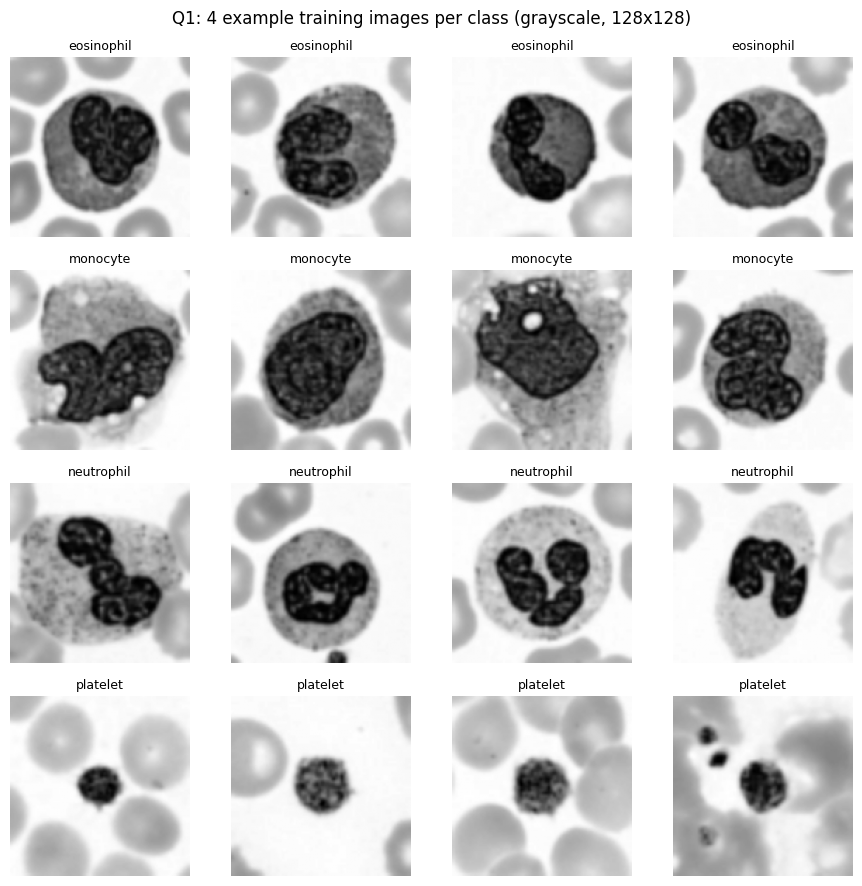

In [5]:
# Grid: 4 example training images for each class (one row per class)
fig, axes = plt.subplots(4, 4, figsize=(9, 9))
for row, cname in enumerate(CLASS_NAMES):
    idx = np.where(y_train == row)[0][:4]
    for col, i in enumerate(idx):
        axes[row, col].imshow(X_train[i], cmap="gray")
        axes[row, col].set_title(cname, fontsize=9)
        axes[row, col].axis("off")
plt.suptitle("Q1: 4 example training images per class (grayscale, 128x128)")
plt.tight_layout()
plt.show()

# Q2. HOG + SVM (6 marks)
HOG settings: 9 orientations, 2×2 cells per block, cell size = our assigned value (8×8).

In [6]:
def extract_hog(img):
    """HOG feature vector of one 128x128 gray image."""
    return hog(img,
               orientations=9,
               pixels_per_cell=(HOG_CELL, HOG_CELL),
               cells_per_block=(2, 2),
               block_norm="L2-Hys")

def hog_features(images):
    return np.array([extract_hog(img) for img in images])

hog_train = hog_features(X_train)
hog_val = hog_features(X_val)

print("HOG feature vector length:", hog_train.shape[1])
print("Train HOG matrix shape   :", hog_train.shape)
print("Val HOG matrix shape     :", hog_val.shape)

# Hand calculation done in code, to double check the printed length
cells_per_side = 128 // HOG_CELL
blocks_per_side = cells_per_side - 1
expected = blocks_per_side * blocks_per_side * (2 * 2 * 9)
print("Expected length from formula:", expected, "| matches:", expected == hog_train.shape[1])

HOG feature vector length: 8100
Train HOG matrix shape   : (400, 8100)
Val HOG matrix shape     : (120, 8100)
Expected length from formula: 8100 | matches: True


### HOG feature length: hand calculation (cell size 8×8)

- Image size = 128 × 128 pixels, cell size = 8 × 8 pixels
- Cells per side = 128 / 8 = **16**, so we have 16 × 16 = 256 cells.
- A block is 2 × 2 cells and moves by 1 cell, so blocks per side = 16 − 2 + 1 = **15**. Total blocks = 15 × 15 = **225**.
- Each cell has a 9-bin histogram, so one block has 2 × 2 × 9 = **36** values.
- Feature length = 225 blocks × 36 = **8100**.

(Compare this with the printed length in the code cell above. If the two numbers differ, check your settings.)

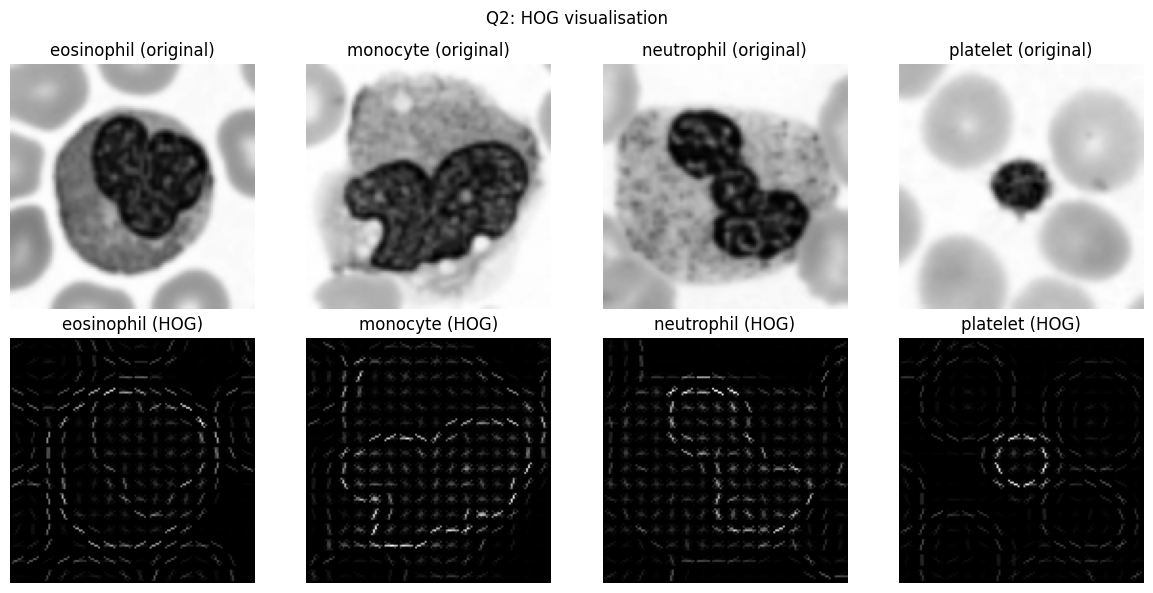

In [7]:
# HOG pictures: one sample image from each class
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for k, cname in enumerate(CLASS_NAMES):
    i = np.where(y_train == k)[0][0]
    _, hog_img = hog(X_train[i], orientations=9,
                     pixels_per_cell=(HOG_CELL, HOG_CELL),
                     cells_per_block=(2, 2), block_norm="L2-Hys",
                     visualize=True)
    axes[0, k].imshow(X_train[i], cmap="gray")
    axes[0, k].set_title(f"{cname} (original)")
    axes[0, k].axis("off")
    axes[1, k].imshow(hog_img, cmap="gray")
    axes[1, k].set_title(f"{cname} (HOG)")
    axes[1, k].axis("off")
plt.suptitle("Q2: HOG visualisation")
plt.tight_layout()
plt.show()

In [8]:
# Helper used for BOTH HOG and SIFT: try C = 0.1, 1, 10 and choose using the VALIDATION set only
def choose_C(Xtr, ytr, Xva, yva, model_name):
    rows = []
    models = {}
    for C in [0.1, 1, 10]:
        clf = LinearSVC(C=C, max_iter=20000, random_state=SEED)
        clf.fit(Xtr, ytr)                       # train on TRAIN only
        pred = clf.predict(Xva)                 # evaluate on VALIDATION
        acc = accuracy_score(yva, pred)
        f1 = f1_score(yva, pred, average="macro")
        rows.append({"C": C, "Val accuracy": acc, "Val macro-F1": f1})
        models[C] = clf
    table = pd.DataFrame(rows)
    # best = highest val accuracy; ties are broken by macro-F1, then by smaller C
    best = max(rows, key=lambda r: (r["Val accuracy"], r["Val macro-F1"], -r["C"]))
    best_C = best["C"]
    print(f"--- {model_name}: validation results for each C ---")
    print(table.to_string(index=False))
    print(f"\nSelected C for {model_name} = {best_C}")
    return models[best_C], best_C, table

hog_model, hog_best_C, hog_table = choose_C(hog_train, y_train, hog_val, y_val, "HOG + SVM")

--- HOG + SVM: validation results for each C ---
   C  Val accuracy  Val macro-F1
 0.1      0.741667      0.738525
 1.0      0.733333      0.730547
10.0      0.733333      0.730547

Selected C for HOG + SVM = 0.1


HOG + SVM  (C = 0.1 )
Validation accuracy : 0.7417
Validation macro-F1 : 0.7385
Confusion matrix (rows = true, columns = predicted):
[[22  3  5  0]
 [ 7 23  0  0]
 [11  5 14  0]
 [ 0  0  0 30]]


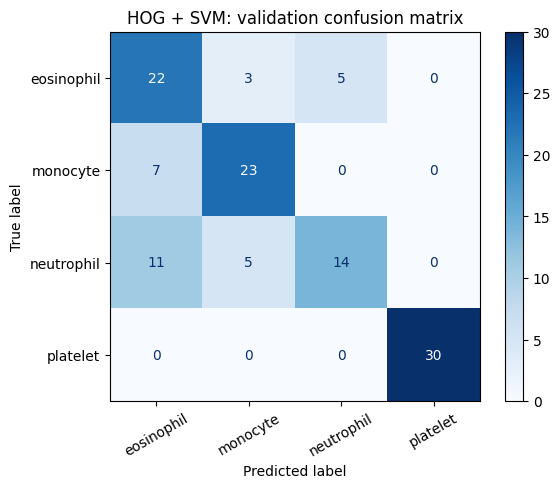

In [9]:
# Report the selected HOG model on the validation set
hog_val_pred = hog_model.predict(hog_val)
hog_val_acc = accuracy_score(y_val, hog_val_pred)
hog_val_f1 = f1_score(y_val, hog_val_pred, average="macro")
cm_hog_val = confusion_matrix(y_val, hog_val_pred)

print("HOG + SVM  (C =", hog_best_C, ")")
print("Validation accuracy :", round(hog_val_acc, 4))
print("Validation macro-F1 :", round(hog_val_f1, 4))
print("Confusion matrix (rows = true, columns = predicted):")
print(cm_hog_val)

ConfusionMatrixDisplay(cm_hog_val, display_labels=CLASS_NAMES).plot(cmap="Blues", xticks_rotation=30)
plt.title("HOG + SVM: validation confusion matrix")
plt.show()

# Q3. SIFT + SVM (7 marks)
### Part 1: Normal SIFT detection on the training images

In [10]:
sift = cv2.SIFT_create()

kp_counts = []
for img in X_train:
    keypoints, descriptors = sift.detectAndCompute(img, None)
    kp_counts.append(len(keypoints))
kp_counts = np.array(kp_counts)

print("Average keypoints per image :", round(kp_counts.mean(), 2))
print("Minimum keypoints           :", kp_counts.min())
print("Maximum keypoints           :", kp_counts.max())
print("Images with zero keypoints  :", int(np.sum(kp_counts == 0)))

Average keypoints per image : 73.21
Minimum keypoints           : 10
Maximum keypoints           : 227
Images with zero keypoints  : 0


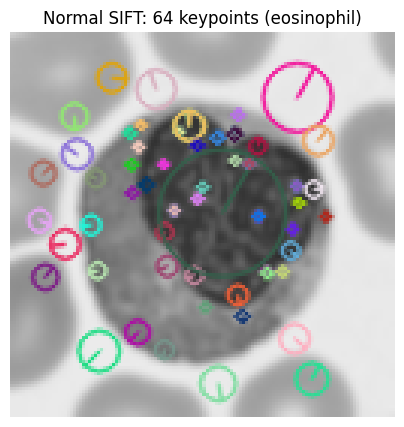

In [11]:
# Draw the detected keypoints on one training image
sample = X_train[0]
kps, _ = sift.detectAndCompute(sample, None)
sample_kp_img = cv2.drawKeypoints(sample, kps, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

plt.figure(figsize=(5, 5))
plt.imshow(sample_kp_img)           # drawKeypoints returns a colour image
plt.title(f"Normal SIFT: {len(kps)} keypoints ({CLASS_NAMES[y_train[0]]})")
plt.axis("off")
plt.show()

**Why is a different number of keypoints per image a problem for an SVM?**
An SVM needs every image to be a feature vector of the *same length*, but normal SIFT gives each image a different number of 128-value descriptors (so the vectors have different sizes and the keypoints are not at matching positions).

### Part 2: Fixed-grid SIFT
We place keypoints on a regular grid (our grid = 4×4) over the 128×128 image, each with size 32, and compute a SIFT descriptor at every grid point using `sift.compute`. Every image now gives the same number of descriptors, which we join into one vector.

In [12]:
def make_grid_keypoints(grid=GRID, size=32, img_size=128):
    """Keypoints at the centres of a grid x grid layout over the image."""
    step = img_size / grid
    kps = []
    for r in range(grid):
        for c in range(grid):
            x = step * (c + 0.5)
            y = step * (r + 0.5)
            kps.append(cv2.KeyPoint(float(x), float(y), size))
    return kps

def extract_sift(img):
    kps = make_grid_keypoints()
    kps, des = sift.compute(img, kps)            # one 128-value descriptor per grid point
    assert des.shape == (GRID * GRID, 128), "unexpected descriptor shape"
    return des.flatten()                         # join into one long vector

def sift_features(images):
    return np.array([extract_sift(img) for img in images])

sift_train = sift_features(X_train)
sift_val = sift_features(X_val)

print("SIFT feature vector length:", sift_train.shape[1])
print("Train SIFT matrix shape   :", sift_train.shape)
print("Val SIFT matrix shape     :", sift_val.shape)
print("Formula check:", GRID * GRID, "grid points x 128 =", GRID * GRID * 128)

SIFT feature vector length: 2048
Train SIFT matrix shape   : (400, 2048)
Val SIFT matrix shape     : (120, 2048)
Formula check: 16 grid points x 128 = 2048


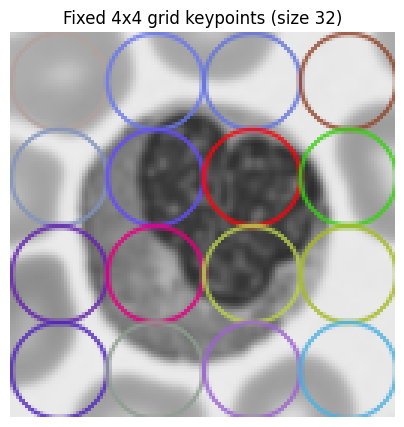

In [13]:
# Picture: the fixed grid keypoints drawn on the same sample image
grid_kps = make_grid_keypoints()
grid_img = cv2.drawKeypoints(sample, grid_kps, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5))
plt.imshow(grid_img)
plt.title(f"Fixed {GRID}x{GRID} grid keypoints (size 32)")
plt.axis("off")
plt.show()

### SIFT feature length: hand calculation (4×4 grid)

- Grid = 4 × 4 = **16** keypoints per image.
- One SIFT descriptor has **128** values (4 × 4 spatial bins × 8 orientation bins = 128).
- Feature length = 16 × 128 = **2048**.

(Compare this with the printed length in the code cell above.)

In [14]:
# Train LinearSVC on SIFT features, choose C using the validation set
sift_model, sift_best_C, sift_table = choose_C(sift_train, y_train, sift_val, y_val, "SIFT + SVM")

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


--- SIFT + SVM: validation results for each C ---
   C  Val accuracy  Val macro-F1
 0.1          0.75      0.753989
 1.0          0.75      0.753989
10.0          0.75      0.753989

Selected C for SIFT + SVM = 0.1


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


SIFT + SVM  (C = 0.1 )
Validation accuracy : 0.75
Validation macro-F1 : 0.754
Confusion matrix (rows = true, columns = predicted):
[[19  9  2  0]
 [ 7 22  1  0]
 [ 8  2 20  0]
 [ 0  0  1 29]]


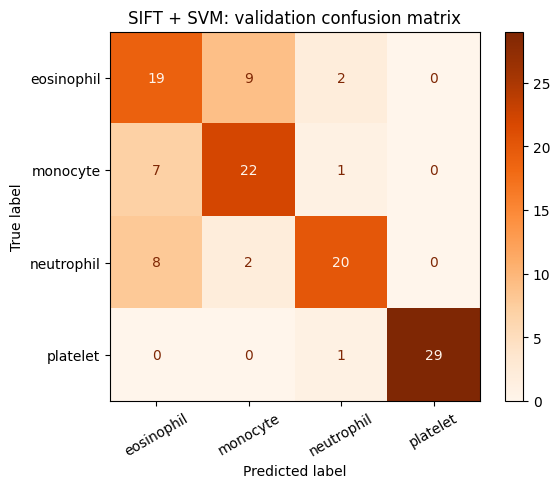

In [15]:
# Report the selected SIFT model on the validation set
sift_val_pred = sift_model.predict(sift_val)
sift_val_acc = accuracy_score(y_val, sift_val_pred)
sift_val_f1 = f1_score(y_val, sift_val_pred, average="macro")
cm_sift_val = confusion_matrix(y_val, sift_val_pred)

print("SIFT + SVM  (C =", sift_best_C, ")")
print("Validation accuracy :", round(sift_val_acc, 4))
print("Validation macro-F1 :", round(sift_val_f1, 4))
print("Confusion matrix (rows = true, columns = predicted):")
print(cm_sift_val)

ConfusionMatrixDisplay(cm_sift_val, display_labels=CLASS_NAMES).plot(cmap="Oranges", xticks_rotation=30)
plt.title("SIFT + SVM: validation confusion matrix")
plt.show()

In [16]:
# Small summary of Q2 and Q3 (all values come from the cells above)
summary = pd.DataFrame({
    "Model": ["HOG + SVM", "SIFT + SVM"],
    "Feature length": [hog_train.shape[1], sift_train.shape[1]],
    "Best C": [hog_best_C, sift_best_C],
    "Val accuracy": [round(hog_val_acc, 4), round(sift_val_acc, 4)],
    "Val macro-F1": [round(hog_val_f1, 4), round(sift_val_f1, 4)],
})
print(summary.to_string(index=False))

     Model  Feature length  Best C  Val accuracy  Val macro-F1
 HOG + SVM            8100     0.1        0.7417        0.7385
SIFT + SVM            2048     0.1        0.7500        0.7540


**Per-class report (precision, recall, F1)**

In [22]:
from sklearn.metrics import classification_report

print("HOG + SVM (validation)")
print(classification_report(y_val, hog_val_pred, target_names=CLASS_NAMES, digits=3))
print("SIFT + SVM (validation)")
print(classification_report(y_val, sift_val_pred, target_names=CLASS_NAMES, digits=3))

HOG + SVM (validation)
              precision    recall  f1-score   support

  eosinophil      0.550     0.733     0.629        30
    monocyte      0.742     0.767     0.754        30
  neutrophil      0.737     0.467     0.571        30
    platelet      1.000     1.000     1.000        30

    accuracy                          0.742       120
   macro avg      0.757     0.742     0.739       120
weighted avg      0.757     0.742     0.739       120

SIFT + SVM (validation)
              precision    recall  f1-score   support

  eosinophil      0.559     0.633     0.594        30
    monocyte      0.667     0.733     0.698        30
  neutrophil      0.833     0.667     0.741        30
    platelet      1.000     0.967     0.983        30

    accuracy                          0.750       120
   macro avg      0.765     0.750     0.754       120
weighted avg      0.765     0.750     0.754       120



# Q4. Robustness (6 marks)
### Prediction (written BEFORE running the robustness test)

> **Student task:** the text below is a draft. Read it, change it to your own opinion if you disagree, and keep it as it is *before* you run the next code cells. Do not edit it after seeing the results.

- **Rotation:** I think **HOG + SVM** will lose more accuracy under 20° rotation, because HOG stores the gradient directions in fixed cells, so rotating the cell shifts every edge direction and the positions in the vector. *(Fixed-grid SIFT is also not rotation-invariant, so this is only my guess.)*
- **Noise:** I think **HOG + SVM** will lose more accuracy under noise, because HOG is built from pixel gradients and random noise creates many strong false edges, while SIFT's descriptors are larger (keypoint size 32) and Gaussian smoothing inside SIFT reduces the noise.

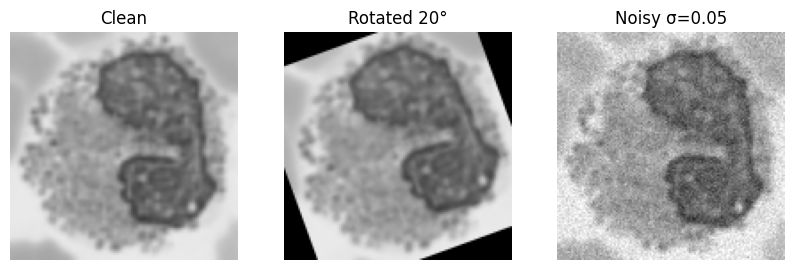

In [17]:
# Freeze both models: from now on we only call .predict(), we never train again
frozen_hog_model = hog_model
frozen_sift_model = sift_model

def rotate_images(images, angle=20):
    """Rotate each 128x128 image by `angle` degrees around its centre."""
    M = cv2.getRotationMatrix2D((64, 64), angle, 1.0)
    return np.array([cv2.warpAffine(img, M, (128, 128)) for img in images], dtype=np.uint8)

def add_noise(images, sigma=0.05, seed=SEED):
    """Scale to 0-1, add Gaussian noise (sigma=0.05), clip to 0-1, scale back to 0-255."""
    noise_rng = np.random.RandomState(seed)
    scaled = images.astype(np.float32) / 255.0
    noisy = scaled + noise_rng.normal(0, sigma, size=scaled.shape)
    noisy = np.clip(noisy, 0, 1)
    return np.round(noisy * 255).astype(np.uint8)

# The change is applied to the IMAGES, before feature extraction
X_test_rot = rotate_images(X_test, 20)
X_test_noisy = add_noise(X_test, 0.05)

# Sanity picture of the three test conditions
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
for ax, im, title in zip(axes, [X_test[0], X_test_rot[0], X_test_noisy[0]], ["Clean", "Rotated 20°", "Noisy σ=0.05"]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.show()

In [18]:
# Evaluate both frozen models on the TEST set (first time we touch it)
def test_accuracy(model, feature_function, images):
    feats = feature_function(images)        # features are extracted AFTER the transformation
    return accuracy_score(y_test, model.predict(feats))

results = {
    "Model": ["HOG + SVM", "SIFT + SVM"],
    "Clean accuracy": [
        test_accuracy(frozen_hog_model, hog_features, X_test),
        test_accuracy(frozen_sift_model, sift_features, X_test),
    ],
    "Rotated accuracy": [
        test_accuracy(frozen_hog_model, hog_features, X_test_rot),
        test_accuracy(frozen_sift_model, sift_features, X_test_rot),
    ],
    "Noisy accuracy": [
        test_accuracy(frozen_hog_model, hog_features, X_test_noisy),
        test_accuracy(frozen_sift_model, sift_features, X_test_noisy),
    ],
}
results_table = pd.DataFrame(results)
results_table["Drop (rotation)"] = results_table["Clean accuracy"] - results_table["Rotated accuracy"]
results_table["Drop (noise)"] = results_table["Clean accuracy"] - results_table["Noisy accuracy"]
print(results_table.round(4).to_string(index=False))

     Model  Clean accuracy  Rotated accuracy  Noisy accuracy  Drop (rotation)  Drop (noise)
 HOG + SVM          0.7417            0.7000          0.5333           0.0417        0.2083
SIFT + SVM          0.7500            0.4917          0.7083           0.2583        0.0417


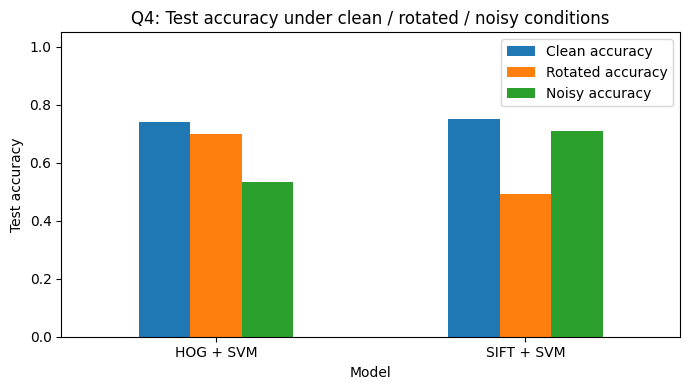

In [19]:
# Bar chart of the comparison table
ax = results_table.set_index("Model")[["Clean accuracy", "Rotated accuracy", "Noisy accuracy"]].plot(
    kind="bar", figsize=(7, 4), rot=0)
ax.set_ylabel("Test accuracy")
ax.set_ylim(0, 1.05)
ax.set_title("Q4: Test accuracy under clean / rotated / noisy conditions")
plt.tight_layout()
plt.show()

### Was my prediction correct? (exactly three sentences)

Under rotation, SIFT lost more accuracy (25.83 vs 4.17 points from clean), so my prediction that HOG would lose more was wrong.
Under noise, HOG lost more accuracy (20.83 vs 4.17 points), so my noise prediction was correct.
Overall, neither model is best in every condition: HOG is more reliable under rotation (0.7000 vs 0.4917), while SIFT is more reliable under noise (0.7083 vs 0.5333).

# Q5. Short Answers and AI Log (3 marks)

**(a) Why does HOG use block normalisation?**
Lighting and contrast change the size of the gradients, so the same shape can give very different histogram values. HOG groups cells into overlapping blocks and normalises the histogram values inside each block, so the features depend on the local shape and not on brightness or contrast. This makes the features more stable and easier for the SVM to use.

**(b) Why is it wrong to choose C using the test set?**
If we pick the C that gives the best test score, the test set has helped to build the model, so it is no longer unseen data. The reported test accuracy becomes too optimistic and does not show how the model will behave on new images. C must be chosen using the validation set, and the test set must be used only once at the end.

In [20]:
# Q5(c): find the two classes confused most, using the VALIDATION confusion matrices (test set is reserved for Q4)
def most_confused_pair(cm):
    best_pair, best_count = None, -1
    for i in range(len(CLASS_NAMES)):
        for j in range(i + 1, len(CLASS_NAMES)):
            count = cm[i, j] + cm[j, i]          # mistakes in both directions
            if count > best_count:
                best_pair, best_count = (CLASS_NAMES[i], CLASS_NAMES[j]), count
    return best_pair, best_count

print("HOG + SVM  most confused pair:", most_confused_pair(cm_hog_val))
print("SIFT + SVM most confused pair:", most_confused_pair(cm_sift_val))

HOG + SVM  most confused pair: (('eosinophil', 'neutrophil'), np.int64(16))
SIFT + SVM most confused pair: (('eosinophil', 'monocyte'), np.int64(16))


**(c) Which two classes did the models confuse most, and why might grayscale make this harder?**

> (eosinophil', 'neutrophil) and ('eosinophil', 'monocyte').

On the validation set, HOG + SVM confused eosinophil and neutrophil the most (16 mistakes), while SIFT + SVM confused eosinophil and monocyte the most (16 mistakes), so eosinophil was in the most-confused pair for both models. Grayscale may make this harder because these white blood cells are partly told apart by stain colour (eosinophil granules stain reddish-orange), and converting to gray keeps only brightness, so cells with similar size, outline and brightness look alike to HOG and SIFT.

Evidence for Q 5(c), why grayscale is a problem :

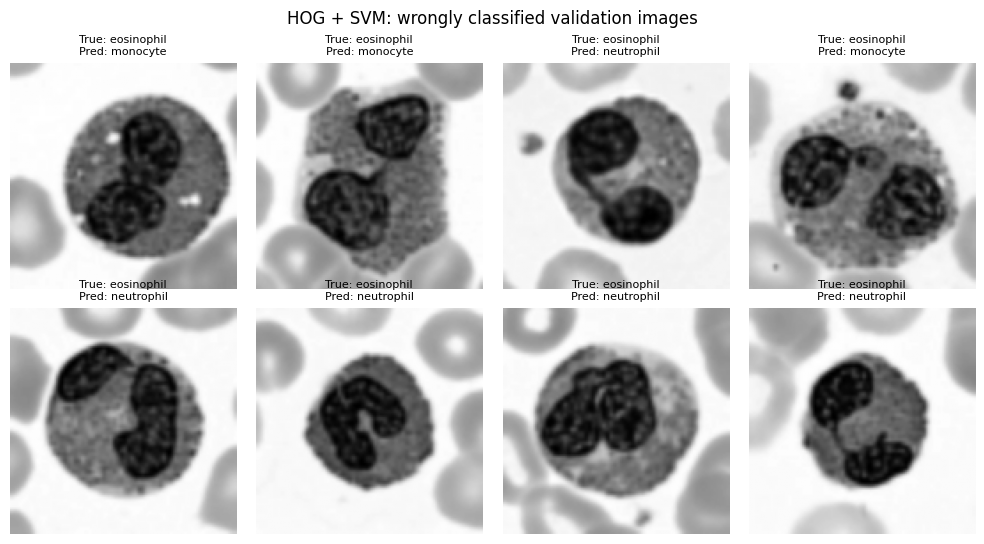

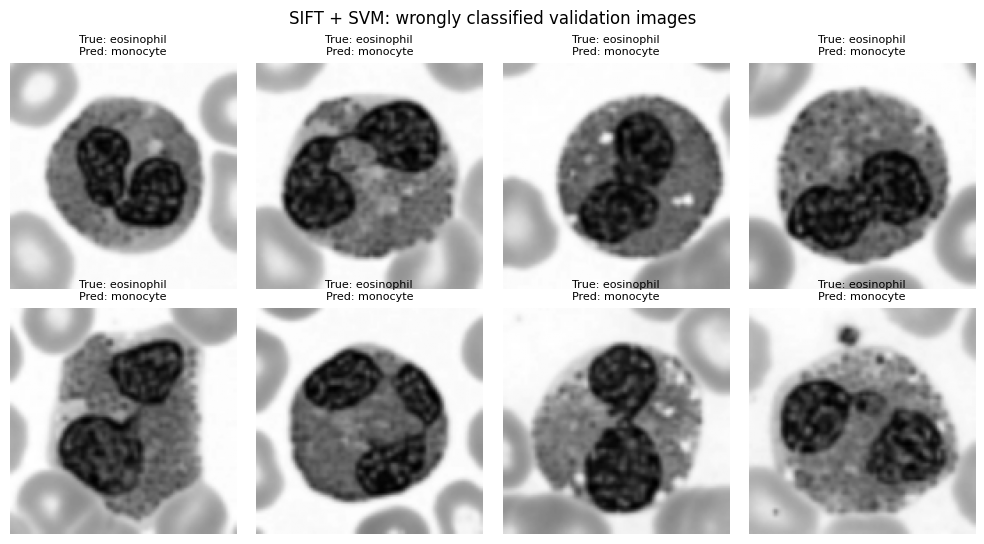

In [23]:
def show_mistakes(pred, title, n=8):
    wrong = np.where(pred != y_val)[0][:n]
    fig, axes = plt.subplots(2, 4, figsize=(10, 5.5))
    for ax, i in zip(axes.ravel(), wrong):
        ax.imshow(X_val[i], cmap="gray")
        ax.set_title(f"True: {CLASS_NAMES[y_val[i]]}\nPred: {CLASS_NAMES[pred[i]]}", fontsize=8)
        ax.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

show_mistakes(hog_val_pred, "HOG + SVM: wrongly classified validation images")
show_mistakes(sift_val_pred, "SIFT + SVM: wrongly classified validation images")

### AI Usage Log



**AI prompt used:** Act as a Computer Vision instructor and help me implement the HOG vs SIFT lab mid exam in Google Colab from the attached PDF."


**What I changed in the generated code:** I added a per-class classification report (precision, recall, F1) for both models on the validation set. I also added a cell that shows wrongly classified validation images with their true and predicted labels, to support my Q5(c) answer. I did not change the dataset, seed, HOG, SIFT or C settings, and I filled in the Q4 and Q5(c) text from my own outputs.


**How I checked the result was correct:**  I compared the printed feature lengths with my hand calculations (HOG 8100 and SIFT 2048, both matched). I checked the printed shapes and class counts in Q1, and looked at the image grid, HOG pictures and SIFT keypoint pictures. I also confirmed that C was chosen on the validation set only, and the test set was used only in Q4.